# Privacy-Aware Android App Permission Management
## Borda-Garrett Ranking + Decision-Tree IF-THEN Rules + Reinforcement Learning

**Category focus:** `Lifestyle & Health`

### Changes relative to the original pipeline

**Decision tree / interaction risk (gamma)**
1. The rule tree is fitted with `class_weight="balanced"`. Unweighted, a majority-malicious base rate makes nearly
   every leaf predict *malicious*, so every app matched a rule and `InteractionRisk` was close to a constant.
2. `NOT X` rule conditions are checked against the app's **request**, not its grants, so denying a permission can
   never fire a rule.
3. Rule strength is **excess risk over the base rate**; a rule needs ≥ 2 granted permissions.
4. Rules are mined from a **rule forest** (selected tree + bootstrap trees); only statistically significant,
   non-duplicate rules are kept, at most 20. The count is never below the previous method's (assert in Section 11).
5. The gamma term charges the **increase** in interaction risk caused by each grant, so the episode penalty is
   exactly `GAMMA × final InteractionRisk`.

**RL workflow**
6. Classifier risk for RL training apps is **cross-fitted** (fold models), so training rewards match what the agent
   sees on validation/test. The state also includes the request mask and the app's risk band.

**Accuracy / precision**
7. `Price`, `Rating`, `IsPaid` added to the classifier (they were silently dropped).
8. Two extra text-risk views (character n-grams; package / related-app tokens), and all text models also learn from
   apps outside Lifestyle & Health, which never enter validation or test.
9. The privacy-score threshold is chosen robustly: among thresholds whose validation accuracy is within 0.5 pp of
   the best (same precision / recall constraints as before), the one with the highest F1 is used.

The last section compares the test metrics with the original pipeline run on the same Lifestyle & Health split.

## 2. Imports and Configuration

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import os
import json
import random
import itertools

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import norm

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier, _tree
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import chi2, mutual_info_classif
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    roc_auc_score, average_precision_score, classification_report, confusion_matrix
)

try:
    import lightgbm as lgb
    HAS_LGB = True
except (ImportError, OSError):   # OSError: lightgbm installed but its OpenMP runtime is missing
    HAS_LGB = False

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
print("LightGBM available:", HAS_LGB)

LightGBM available: True


In [2]:
# ---------------------------------------------------------------
# Reproducibility
# ---------------------------------------------------------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

# ---------------------------------------------------------------
# Project configuration
# ---------------------------------------------------------------
CATEGORY = "Lifestyle & Health"
# The raw `Category` column has no literal "Lifestyle & Health" value. These genres are mapped onto the
# broad project category with the same BROAD_CATEGORY_MAP used for the Borda-Garrett weights.
CATEGORY_RAW_VALUES = ['Travel & Local', 'Personalization', 'Lifestyle', 'Health & Fitness', 'Sports', 'Transportation', 'Shopping', 'Medical', 'Weather']

DATA_PATH = "Android_Permission.csv"          # pandas reads the .gz directly
WEIGHTS_PATH = "combined_weights_lifestyle_health.csv"   # written in Section 9 from TRAIN data only
REFERENCE_WEIGHTS_PATH = "combined_weights_social_communication.csv"  # optional, comparison only
OUTPUT_DIR = "results_RL_lifestyle_health"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TOP_K = 12

# Price and Rating were previously dropped together with the non-permission columns. Price alone has a
# Spearman correlation of ~0.36 with Class among Games apps, so it is kept as classifier metadata.
METADATA_FEATURES = ["Number of ratings", "Dangerous permissions count", "Safe permissions count",
                     "Price", "Rating"]

MIN_RAW_PERMISSION_SUPPORT = 0.005   # fraction of TRAIN apps that must request a raw permission
SMOTE_TARGET_RATIO = 1.0
N_CV_FOLDS = 5

# ---- Precision focus --------------------------------------------------------
# Final threshold = most accurate threshold on VALIDATION whose bootstrap-lower-bound precision >= PRECISION_TARGET.
PRECISION_TARGET = 0.85
FALLBACK_BETA = 0.5          # F-beta used if no threshold reaches the target (beta<1 favours precision)
MIN_RECALL_FLOOR = 0.40      # guard so the constraint can't be met by flagging only a handful of apps
THRESH_N_BOOT = 500          # bootstrap resamples of VALIDATION used to get a conservative precision estimate
THRESH_PRECISION_QUANTILE = 0.10   # the 10th-percentile precision must clear PRECISION_TARGET
THRESH_ACC_TOLERANCE = 0.005       # thresholds within 0.5 pp of the best feasible accuracy count as tied


COEF_CANDIDATES = [
    (0.40, 0.20, 0.10),
    (0.50, 0.20, 0.15),
    (0.60, 0.25, 0.15),
    (0.70, 0.20, 0.10),
    (0.80, 0.30, 0.20),
    (0.90, 0.35, 0.25),
    (0.60, 0.40, 0.20),
]

# Q-learning
QL_ALPHA = 0.1
QL_GAMMA = 0.9
QL_PASSES = 3                # episodes = QL_PASSES * len(balanced train set)
QL_EPS_START = 1.0
QL_EPS_MIN = 0.05
QL_EPS_DECAY = 0.9995

# Text risk: non-Games apps never appear in validation/test, so adding them to the text-model fits
# gives ~23k extra labelled descriptions without touching evaluation rows.
TEXT_AUGMENT_WITH_OTHER_CATEGORIES = True

# Decision-tree interaction rules (gamma term)
RULE_MIN_LEAF_SUPPORT = 30       # a leaf needs this many TRAIN apps to become a rule
INTERACTION_MIN_GRANTED = 2      # an *interaction* needs at least two granted permissions
RULE_FOREST_TREES = 60           # bootstrap trees whose root-to-leaf paths are mined as extra rules
RULE_FOREST_DEPTH = 5
RULE_FOREST_MIN_LEAF = 25
RULE_MAX_PVALUE = 0.05           # keep only rules significantly above the base rate (one-sided binomial)
RULE_MAX_OVERLAP = 0.95          # drop a near-duplicate: >= 95% of its TRAIN apps shared (Jaccard) with a stronger rule
RULE_MAX_COUNT = 20              # keep the rule list short enough to read and report

# RL state: the app's classifier-risk band (quantile bins on TRAIN)
RL_RISK_BINS = 5

PRIVACY_LOW_THRESHOLD = 0.33
PRIVACY_HIGH_THRESHOLD = 0.67

print("CATEGORY:", CATEGORY, "<- raw Category values:", CATEGORY_RAW_VALUES)
print("TOP_K:", TOP_K, "| PRECISION_TARGET:", PRECISION_TARGET)
print("Reward coefficient candidates:", COEF_CANDIDATES)

CATEGORY: Lifestyle & Health <- raw Category values: ['Travel & Local', 'Personalization', 'Lifestyle', 'Health & Fitness', 'Sports', 'Transportation', 'Shopping', 'Medical', 'Weather']
TOP_K: 12 | PRECISION_TARGET: 0.85
Reward coefficient candidates: [(0.4, 0.2, 0.1), (0.5, 0.2, 0.15), (0.6, 0.25, 0.15), (0.7, 0.2, 0.1), (0.8, 0.3, 0.2), (0.9, 0.35, 0.25), (0.6, 0.4, 0.2)]


## 3. Load Dataset

In [3]:
df = pd.read_csv(DATA_PATH, low_memory=False)
print("Dataset shape:", df.shape)
missing_counts = df.isna().sum()
print("\nMissing values (columns with >0):")
print(missing_counts[missing_counts > 0])
print("\nClass distribution (0 = Benign, 1 = Malicious):")
print(df["Class"].value_counts())
print(f"\n{CATEGORY} genre rows in the raw data:")
print(df.loc[df["Category"].isin(CATEGORY_RAW_VALUES), "Category"].value_counts())

Dataset shape: (29999, 184)

Missing values (columns with >0):
App                              1
Description                      3
Related apps                   755
Dangerous permissions count    204
dtype: int64

Class distribution (0 = Benign, 1 = Malicious):
Class
1    20000
0     9999
Name: count, dtype: int64

Lifestyle & Health genre rows in the raw data:
Category
Travel & Local      2154
Personalization     1527
Lifestyle           1435
Health & Fitness    1038
Sports               632
Transportation       434
Shopping             401
Medical              270
Weather              173
Name: count, dtype: int64


## 5. Data Validation

Same 12-permission aggregation map as the Social & Communication notebook, so results are comparable
across categories. Missing columns are reported, never fabricated.

In [4]:
PERMISSION_COLUMN_MAP = {
    "Camera": ["Hardware controls : take pictures and videos (D)"],
    "Location": [
        "Your location : coarse (network-based) location (D)",
        "Your location : fine (GPS) location (D)",
        "Default : coarse (network-based) location (S)",
    ],
    "Contacts": [
        "Your personal information : read contact data (D)",
        "Your personal information : write contact data (D)",
        "Default : write contact data (S)",
        "Your accounts : contacts data in Google accounts (D)",
    ],
    "Microphone": ["Hardware controls : record audio (D)"],
    "Storage": [
        "Storage : modify/delete USB storage contents modify/delete SD card contents (D)",
        "Default : modify/delete USB storage contents modify/delete SD card contents (S)",
    ],
    "SMS": [
        "Services that cost you money : send SMS messages (D)",
        "Your messages : edit SMS or MMS (D)",
        "Your messages : read SMS or MMS (D)",
        "Your messages : receive SMS (D)",
        "Your messages : receive MMS (D)",
        "Your messages : send SMS-received broadcast (S)",
    ],
    "CallLogs": [],
    "Bluetooth": [
        "Network communication : create Bluetooth connections (D)",
        "System tools : bluetooth administration (D)",
    ],
    "Calendar": [
        "Your personal information : add or modify calendar events and send email to guests (D)",
        "Your personal information : read calendar events (D)",
    ],
    "PhoneState": [
        "Default : read phone state and identity (S)",
        "Phone calls : read phone state and identity (D)",
    ],
    "Internet": [
        "Default : full Internet access (S)",
        "Network communication : full Internet access (D)",
    ],
    "ReadPhoneNumbers": [],
}
PERMISSION_NAMES = list(PERMISSION_COLUMN_MAP.keys())

missing_report = {k: [c for c in v if c not in df.columns] for k, v in PERMISSION_COLUMN_MAP.items()}
missing_report = {k: v for k, v in missing_report.items() if v}
print("Missing mapped columns:", missing_report if missing_report else "none")
print("Permissions with NO raw column in this dataset (constant 0):",
      [p for p, c in PERMISSION_COLUMN_MAP.items() if len(c) == 0])

Missing mapped columns: none
Permissions with NO raw column in this dataset (constant 0): ['CallLogs', 'ReadPhoneNumbers']


## 6. Category Filtering

In [5]:
df["BroadCategory"] = np.where(df["Category"].isin(CATEGORY_RAW_VALUES), CATEGORY, "Other")
print(df["BroadCategory"].value_counts())

cat_df = df[df["BroadCategory"] == CATEGORY].copy().reset_index(drop=True)
print(f"\nApps in category '{CATEGORY}':", len(cat_df))
print("Benign  (Class=0):", (cat_df["Class"] == 0).sum())
print("Malicious (Class=1):", (cat_df["Class"] == 1).sum())
print("\nMalicious rate by genre:")
print(cat_df.groupby("Category")["Class"].agg(["count", "mean"]).round(3))

BroadCategory
Other                 21935
Lifestyle & Health     8064
Name: count, dtype: int64

Apps in category 'Lifestyle & Health': 8064
Benign  (Class=0): 1706
Malicious (Class=1): 6358

Malicious rate by genre:
                  count   mean
Category                      
Health & Fitness   1038  0.487
Lifestyle          1435  0.614
Medical             270  0.989
Personalization    1527  0.678
Shopping            401  0.920
Sports              632  0.964
Transportation      434  0.991
Travel & Local     2154  0.985
Weather             173  0.803


## 7. Permission Matrix + Feature Engineering

12 aggregated permission flags (RL-visible), raw permission columns (classifier-only), metadata,
and engineered features. All engineered features are derived from existing columns.

In [6]:
def build_permission_matrix(source_df, colmap):
    out = {}
    for perm, cols in colmap.items():
        present = [c for c in cols if c in source_df.columns]
        out[perm] = ((source_df[present].apply(pd.to_numeric, errors="coerce").fillna(0).sum(axis=1) > 0)
                     .astype(int) if present else pd.Series(0, index=source_df.index))
    return pd.DataFrame(out)

perm_feats = build_permission_matrix(cat_df, PERMISSION_COLUMN_MAP)

parts = {
    "App": cat_df["App"].fillna("").values,
    "Category": cat_df["Category"].values
}

# Add permission-level aggregated features
for p in PERMISSION_NAMES:
    parts[p] = perm_feats[p].values

# Add ONLY original metadata features here
BASE_METADATA_FEATURES = [
    "Dangerous permissions count",
    "Safe permissions count",
    "Number of ratings",
    "Price",
    "Rating"
]

for m in BASE_METADATA_FEATURES:
    if m in cat_df.columns:
        parts[m] = pd.to_numeric(
            cat_df[m], errors="coerce"
        ).fillna(0).values

permission_matrix = pd.DataFrame(parts)

# --- Engineered metadata ---------------------------------------------------------------
permission_matrix["PermissionCount"] = permission_matrix[PERMISSION_NAMES].sum(axis=1)
_d = permission_matrix["Dangerous permissions count"].astype(float)
_s = permission_matrix["Safe permissions count"].astype(float)
permission_matrix["DangerousToSafeRatio"] = (_d / (_d + _s + 1e-6)).clip(0, 1)
permission_matrix["LogNumRatings"] = np.log1p(permission_matrix["Number of ratings"].clip(lower=0))
permission_matrix["DescriptionLength"] = cat_df["Description"].fillna("").str.len().values
permission_matrix["IsPaid"] = (permission_matrix["Price"] > 0).astype(int)

GENRE_FEATURES = [f"Genre_{g}" for g in CATEGORY_RAW_VALUES]
for g, col in zip(CATEGORY_RAW_VALUES, GENRE_FEATURES):
    permission_matrix[col] = (permission_matrix["Category"] == g).astype(int)

ENGINEERED_METADATA_FEATURES = ["PermissionCount", "DangerousToSafeRatio", "LogNumRatings", "DescriptionLength", "IsPaid"]
METADATA_FEATURES = METADATA_FEATURES + ENGINEERED_METADATA_FEATURES + GENRE_FEATURES

# --- Raw permission columns for the classifier -----------------------------------------
NON_PERMISSION_COLUMNS = {
    "App", "Package", "Category", "BroadCategory", "Description", "Related apps",
    "Rating", "Number of ratings", "Price",
    "Dangerous permissions count", "Safe permissions count", "Class",
}
RAW_PERMISSION_COLUMNS_ALL = [c for c in df.columns if c not in NON_PERMISSION_COLUMNS]
raw_block = cat_df[RAW_PERMISSION_COLUMNS_ALL].apply(pd.to_numeric, errors="coerce").fillna(0).astype(int)
permission_matrix = pd.concat([permission_matrix, raw_block.reset_index(drop=True)], axis=1)

# Text used for the text-risk features (Section 11b). Kept in side arrays, not model features themselves.
def _app_text(frame):
    return (frame["App"].fillna("") + " . " + frame["Description"].fillna("")).values

def _package_text(frame):
    # Package name and related-app package names split into tokens (developer / ecosystem signal).
    return (frame["Package"].fillna("").str.replace(".", " ", regex=False) + " "
            + frame["Related apps"].fillna("").str.replace(r"[{},.]", " ", regex=True)).values

APP_TEXT, PKG_TEXT = _app_text(cat_df), _package_text(cat_df)
_other_df = df[df["BroadCategory"] != CATEGORY]
OTHER_APP_TEXT, OTHER_PKG_TEXT = _app_text(_other_df), _package_text(_other_df)
OTHER_Y = _other_df["Class"].astype(int).values

permission_matrix["LabelEncoded"] = cat_df["Class"].astype(int).values
permission_matrix["uid"] = np.arange(len(permission_matrix))

RAW_TO_AGG = {c: perm for perm, cols in PERMISSION_COLUMN_MAP.items() for c in cols}

print("permission_matrix shape:", permission_matrix.shape)
print(f"\nPermission support (fraction of {CATEGORY} apps):")
print(permission_matrix[PERMISSION_NAMES].mean().round(4).sort_values(ascending=False))

permission_matrix shape: (8064, 208)

Permission support (fraction of Lifestyle & Health apps):
Internet            0.7809
Location            0.3992
Storage             0.3395
PhoneState          0.2810
Camera              0.0926
Contacts            0.0904
SMS                 0.0572
Microphone          0.0368
Bluetooth           0.0262
Calendar            0.0205
CallLogs            0.0000
ReadPhoneNumbers    0.0000
dtype: float64


## 8. Train / Validation / Test Split (70 / 15 / 15, Stratified)

Happens **before** weight computation, rule mining, text modelling, classifier training and RL training.
Stratified on the label *and* genre so every genre is represented proportionally in each split.

In [7]:
strat_key = permission_matrix["LabelEncoded"].astype(str) + "_" + permission_matrix["Category"]
# Genre strata with fewer than 10 apps (e.g. benign Medical apps) cannot be split three ways; fold each into
# the largest genre stratum of the same label so the split stays stratified on the label.
_counts = strat_key.value_counts()
_largest = {lab: _counts[[k for k in _counts.index if k.startswith(lab + "_")]].idxmax() for lab in ("0", "1")}
strat_key = strat_key.where(strat_key.map(_counts) >= 10,
                            permission_matrix["LabelEncoded"].astype(str).map(_largest))
train_df, temp_df = train_test_split(permission_matrix, test_size=0.30, stratify=strat_key,
                                     random_state=RANDOM_STATE)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=strat_key.loc[temp_df.index],
                                   random_state=RANDOM_STATE)
train_df, val_df, test_df = train_df.copy(), val_df.copy(), test_df.copy()

for n, d in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    print(f"{n:5s}: {d.shape}  malicious rate: {d['LabelEncoded'].mean():.3f}")

assert set(train_df.index).isdisjoint(val_df.index)
assert set(train_df.index).isdisjoint(test_df.index)
assert set(val_df.index).isdisjoint(test_df.index)
print("\nVerified: train / validation / test indices are mutually disjoint.")

# Classifier raw-permission features: support measured on TRAIN only
_raw_support = train_df[RAW_PERMISSION_COLUMNS_ALL].mean()
CLF_PERMISSION_FEATURES = [c for c in RAW_PERMISSION_COLUMNS_ALL
                           if train_df[c].nunique() > 1 and _raw_support[c] >= MIN_RAW_PERMISSION_SUPPORT]
print(f"\nRaw permission columns kept for classifier (support >= {MIN_RAW_PERMISSION_SUPPORT} on TRAIN):",
      len(CLF_PERMISSION_FEATURES))

Train: (5644, 208)  malicious rate: 0.788
Val  : (1210, 208)  malicious rate: 0.788
Test : (1210, 208)  malicious rate: 0.788

Verified: train / validation / test indices are mutually disjoint.

Raw permission columns kept for classifier (support >= 0.005 on TRAIN): 49


### 9b. Load & validate the Lifestyle & Health weights file

In [8]:
weights_df = pd.read_csv(WEIGHTS_PATH)
weight_sum = weights_df["CombinedWeight"].sum()
print("Sum of CombinedWeight:", weight_sum)
if not np.isclose(weight_sum, 1.0, atol=1e-2):
    weights_df["CombinedWeight"] /= weight_sum
    print("Normalised to sum 1.")
weights_df = weights_df.sort_values("CombinedWeight", ascending=False).reset_index(drop=True)
weights_df["Rank"] = weights_df.index + 1
weight_map = dict(zip(weights_df["Permission"], weights_df["CombinedWeight"]))

if os.path.exists(REFERENCE_WEIGHTS_PATH):
    ref = pd.read_csv(REFERENCE_WEIGHTS_PATH).rename(columns={"CombinedWeight": "SocialComm_Weight"})
    weights_df = weights_df.merge(ref, on="Permission", how="left")
    print("Social & Communication weights shown for comparison only (not used).")
weights_df

Sum of CombinedWeight: 0.9999999999999994
Social & Communication weights shown for comparison only (not used).


,Permission,CombinedWeight,Rank,SocialComm_Weight
0,SMS,0.117430,1,0.080030
1,Bluetooth,0.113576,2,0.088193
2,Location,0.104215,3,0.105413
3,Contacts,0.104063,4,0.080030
4,Camera,0.096052,5,0.100210
5,Internet,0.089390,6,0.105413
6,Microphone,0.084187,7,0.097402
7,Storage,0.084035,8,0.104215
8,PhoneState,0.076024,9,0.100058
9,Calendar,0.076024,10,0.084035


## 10. Top Permission Selection (RL action space)

In [9]:
top_permissions = weights_df.head(TOP_K)["Permission"].tolist()
RL_FEATURES = top_permissions
print(f"TOP_{TOP_K} permissions for the RL state/action space:", top_permissions)
weights_df.head(TOP_K)[["Rank", "Permission", "CombinedWeight"]]

TOP_12 permissions for the RL state/action space: ['SMS', 'Bluetooth', 'Location', 'Contacts', 'Camera', 'Internet', 'Microphone', 'Storage', 'PhoneState', 'Calendar', 'CallLogs', 'ReadPhoneNumbers']


,Rank,Permission,CombinedWeight
0,1,SMS,0.117430
1,2,Bluetooth,0.113576
2,3,Location,0.104215
3,4,Contacts,0.104063
4,5,Camera,0.096052
5,6,Internet,0.089390
6,7,Microphone,0.084187
7,8,Storage,0.084035
8,9,PhoneState,0.076024
9,10,Calendar,0.076024


## 11. Interpretable Decision-Tree Rules (TRAINING SET ONLY)

The tree uses only `train_df`, the non-constant `RL_FEATURES`, and `LabelEncoded`, with
`class_weight="balanced"`. Without the weighting, a majority-malicious base rate makes almost every leaf
predict *malicious*, so every app matched a "malicious rule" and interaction risk collapsed to roughly the
base rate for everyone.

Each root-to-leaf path is turned into an **interaction rule** for the RL agent:

* `X` conditions (permission present) become **granted** conditions: the rule fires only when the agent has
  granted all of them.
* `NOT X` conditions describe the app's **request profile**: they hold only when the app does not request X.
  A denial never satisfies them.
* Rule strength is the path's **excess risk** over the training base rate,
  `max(0, (P(mal | path) - base) / (1 - base))`, with Laplace smoothing.

**Rule forest.** One shallow tree has only a handful of leaves, so it yields fewer interaction rules than the
previous (unweighted, every-malicious-leaf) method. Paths are therefore mined from the selected tree plus
`RULE_FOREST_TREES` balanced trees fitted on bootstrap samples of TRAIN (the RuleFit / SIRUS idea). Every path is
re-scored on the full TRAIN split; a path becomes a rule if it needs ≥ `INTERACTION_MIN_GRANTED` granted
permissions, covers ≥ `RULE_MIN_LEAF_SUPPORT` training apps and has a malicious rate above the base rate. Paths
covering exactly the same apps are merged (the shortest is kept).

Only rules that are **statistically significant** (one-sided binomial test against the base rate,
p < `RULE_MAX_PVALUE`) are kept, most significant first. A rule sharing ≥ `RULE_MAX_OVERLAP` of its training apps
with a rule already kept is dropped as a near-duplicate, and the list stops at `RULE_MAX_COUNT` rules.

Granting more permissions can only raise interaction risk and denying can only lower it. The test set is not
used for fitting or selection.

In [10]:
# Fit candidate trees only on the original training split; no SMOTE rows or metadata enter rule fitting.
RULE_FEATURES = [p for p in RL_FEATURES if train_df[p].nunique() > 1]   # constant columns cannot split
TREE_CANDIDATES = [(depth, leaf) for depth in range(2, 6) for leaf in (25, 50)]
X_rule_train = train_df[RULE_FEATURES].astype(float)
y_rule_train = train_df["LabelEncoded"].astype(int)
X_rule_val = val_df[RULE_FEATURES].astype(float)
y_rule_val = val_df["LabelEncoded"].astype(int)
BASE_MALICIOUS_RATE = float(y_rule_train.mean())

tree_candidates = []
for depth, leaf in TREE_CANDIDATES:
    candidate = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf,
                                       class_weight="balanced", random_state=RANDOM_STATE)
    candidate.fit(X_rule_train, y_rule_train)
    val_proba = candidate.predict_proba(X_rule_val)[:, list(candidate.classes_).index(1)]
    val_pred = candidate.predict(X_rule_val)
    tree_candidates.append({
        "max_depth": depth, "min_samples_leaf": leaf,
        "tree": candidate,
        "Val_AvgPrecision": average_precision_score(y_rule_val, val_proba),
        "Val_BalancedAccuracy": (recall_score(y_rule_val, val_pred, zero_division=0)
                                 + recall_score(y_rule_val, val_pred, pos_label=0, zero_division=0)) / 2,
        "Leaves": candidate.get_n_leaves(),
    })
tree_selection_df = pd.DataFrame([{k: v for k, v in r.items() if k != "tree"} for r in tree_candidates])
best_ap = tree_selection_df["Val_AvgPrecision"].max()
# Favor the simplest candidate within 0.01 AP of the best; then higher balanced accuracy.
eligible = tree_selection_df[tree_selection_df["Val_AvgPrecision"] >= best_ap - 0.01]
chosen_idx = eligible.sort_values(["max_depth", "Leaves", "Val_BalancedAccuracy", "min_samples_leaf"],
                                  ascending=[True, True, False, False]).index[0]
RULE_TREE = tree_candidates[int(chosen_idx)]["tree"]
print("Decision-tree candidates (validation only):")
display(tree_selection_df.round(4))
print(f"Selected shallowest tree within 0.01 validation AP of best (best AP={best_ap:.4f}).")

def extract_tree_rules(tree, feature_names):
    """Return every root-to-leaf path together with its leaf node id."""
    t = tree.tree_
    found = []
    def walk(node, conditions):
        if t.feature[node] != _tree.TREE_UNDEFINED:
            feature = feature_names[t.feature[node]]
            # Inputs are binary, so <= 0.5 is NOT permission and > 0.5 is permission.
            walk(t.children_left[node], conditions + [(feature, 0)])
            walk(t.children_right[node], conditions + [(feature, 1)])
            return
        found.append({"Node": node, "Conditions": tuple(conditions),
                      "PredictedClass": int(tree.classes_[np.argmax(t.value[node][0])])})
    walk(0, [])
    return found

def format_conditions(conditions):
    if not conditions:
        return "(no conditions)"
    return " AND ".join((f"{name}" if value == 1 else f"NOT {name}") for name, value in conditions)

_train_leaf_ids = RULE_TREE.apply(X_rule_train)
_val_leaf_ids = RULE_TREE.apply(X_rule_val)
rule_rows = []
for rule_number, path in enumerate(extract_tree_rules(RULE_TREE, RULE_FEATURES), start=1):
    node = path["Node"]
    trmask, vamask = _train_leaf_ids == node, _val_leaf_ids == node
    n_train, n_mal = int(trmask.sum()), int(y_rule_train.values[trmask].sum())
    # Counts come from the unweighted TRAIN rows; Laplace smoothing keeps small leaves from reaching 0 or 1.
    p_mal = (n_mal + 1) / (n_train + 2)
    path.update({
        "RuleNumber": rule_number,
        "ConditionsText": format_conditions(path["Conditions"]),
        "GrantedConditions": tuple(f for f, v in path["Conditions"] if v == 1),
        "NotRequestedConditions": tuple(f for f, v in path["Conditions"] if v == 0),
        "TrainingApps": n_train, "TrainingMalicious": n_mal, "TrainingBenign": n_train - n_mal,
        "MaliciousProbability": p_mal,
        "Lift": p_mal / BASE_MALICIOUS_RATE,
        "ExcessRisk": max(0.0, (p_mal - BASE_MALICIOUS_RATE) / (1.0 - BASE_MALICIOUS_RATE)),
        "ValidationSupport": int(vamask.sum()),
        "ValidationMalicious": int(y_rule_val.values[vamask].sum()),
        "ValidationBenign": int(vamask.sum() - y_rule_val.values[vamask].sum()),
        "ValidationMaliciousRate": float(y_rule_val.values[vamask].mean()) if vamask.any() else np.nan,
    })
    rule_rows.append(path)
TREE_RULES = rule_rows
rules_df = pd.DataFrame([{k: v for k, v in row.items() if k not in ("Conditions", "Node")} for row in TREE_RULES])

tree_val_proba = RULE_TREE.predict_proba(X_rule_val)[:, list(RULE_TREE.classes_).index(1)]
tree_val_pred = RULE_TREE.predict(X_rule_val)
print(f"Training base malicious rate: {BASE_MALICIOUS_RATE:.4f}")
print("Selected tree validation performance:")
print({"Accuracy": accuracy_score(y_rule_val, tree_val_pred),
       "Precision": precision_score(y_rule_val, tree_val_pred, zero_division=0),
       "Recall": recall_score(y_rule_val, tree_val_pred, zero_division=0),
       "F1": f1_score(y_rule_val, tree_val_pred, zero_division=0),
       "AveragePrecision": average_precision_score(y_rule_val, tree_val_proba)})
print("Root-to-leaf IF-THEN rules; validation support is shown per leaf:")
display(rules_df[["RuleNumber", "ConditionsText", "PredictedClass", "MaliciousProbability", "Lift", "ExcessRisk",
                  "TrainingApps", "TrainingMalicious", "TrainingBenign", "ValidationSupport",
                  "ValidationMaliciousRate"]].round(4))

# Previous method, for reference: unweighted trees, same selection rule, every malicious-predicted leaf.
_old = []
for depth, leaf in TREE_CANDIDATES:
    t = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=RANDOM_STATE).fit(X_rule_train, y_rule_train)
    _old.append((depth, t.get_n_leaves(), -leaf, average_precision_score(y_rule_val, t.predict_proba(X_rule_val)[:, 1]), t))
_old_best = max(o[3] for o in _old)
_old_tree = sorted([o for o in _old if o[3] >= _old_best - 0.01], key=lambda o: o[:3])[0][4]
PREVIOUS_METHOD_RULE_COUNT = sum(1 for r in extract_tree_rules(_old_tree, RULE_FEATURES)
                                 if r["PredictedClass"] == 1 and r["Conditions"])

# ---- Interaction rules: decision-tree rule forest -------------------------------------------------
from scipy.stats import binomtest

def _path_mask(conditions, X):
    mask = np.ones(len(X), dtype=bool)
    for feature, value in conditions:
        mask &= X[feature].values == value
    return mask

rule_rng = np.random.RandomState(RANDOM_STATE)
rule_trees = [RULE_TREE]
for _ in range(RULE_FOREST_TREES):
    boot = rule_rng.randint(0, len(X_rule_train), len(X_rule_train))
    rule_trees.append(DecisionTreeClassifier(
        max_depth=RULE_FOREST_DEPTH, min_samples_leaf=RULE_FOREST_MIN_LEAF, max_features=0.7,
        class_weight="balanced", random_state=rule_rng.randint(2**31 - 1),
    ).fit(X_rule_train.iloc[boot], y_rule_train.iloc[boot]))

candidate_rules = {}
for t in rule_trees:
    for path in extract_tree_rules(t, RULE_FEATURES):
        conds = tuple(sorted(path["Conditions"]))
        granted = tuple(f for f, v in conds if v == 1)
        if len(granted) < INTERACTION_MIN_GRANTED:
            continue
        trmask = _path_mask(conds, X_rule_train)
        n, k = int(trmask.sum()), int(y_rule_train.values[trmask].sum())
        p_mal = (k + 1) / (n + 2)
        if n < RULE_MIN_LEAF_SUPPORT or p_mal <= BASE_MALICIOUS_RATE:
            continue
        key = trmask.tobytes()   # same covered apps -> same rule; keep the shortest description
        if key in candidate_rules and len(candidate_rules[key]["Conditions"]) <= len(conds):
            continue
        vamask = _path_mask(conds, X_rule_val)
        candidate_rules[key] = {
            "Conditions": conds, "ConditionsText": format_conditions(conds),
            "GrantedConditions": granted,
            "NotRequestedConditions": tuple(f for f, v in conds if v == 0),
            "TrainingApps": n, "TrainingMalicious": k, "MaliciousProbability": p_mal,
            "Lift": p_mal / BASE_MALICIOUS_RATE,
            "ExcessRisk": (p_mal - BASE_MALICIOUS_RATE) / (1.0 - BASE_MALICIOUS_RATE),
            "BinomialPValue": float(binomtest(k, n, BASE_MALICIOUS_RATE, alternative="greater").pvalue),
            "ValidationSupport": int(vamask.sum()),
            "ValidationMaliciousRate": float(y_rule_val.values[vamask].mean()) if vamask.any() else np.nan,
            "_TrainMask": trmask,
        }

# Keep the strongest evidence first: significant rules only, most significant first; skip a rule that mostly
# re-describes the apps of a rule already kept; stop at RULE_MAX_COUNT.
significant_rules = sorted((r for r in candidate_rules.values() if r["BinomialPValue"] < RULE_MAX_PVALUE),
                           key=lambda r: (r["BinomialPValue"], -r["ExcessRisk"], r["ConditionsText"]))
INTERACTION_RULES = []
for r in significant_rules:
    m = r["_TrainMask"]
    if any((m & kept["_TrainMask"]).sum() / (m | kept["_TrainMask"]).sum() >= RULE_MAX_OVERLAP
           for kept in INTERACTION_RULES):
        continue
    INTERACTION_RULES.append(r)
    if len(INTERACTION_RULES) == RULE_MAX_COUNT:
        break
INTERACTION_RULES.sort(key=lambda r: (-r["ExcessRisk"], r["ConditionsText"]))
for number, r in enumerate(INTERACTION_RULES, start=1):
    r["RuleNumber"] = f"I{number}"
interaction_rules_df = pd.DataFrame([{k: v for k, v in r.items() if k not in ("Conditions", "_TrainMask")}
                                     for r in INTERACTION_RULES])

print(f"Candidate paths above base rate: {len(candidate_rules)} | significant (p < {RULE_MAX_PVALUE}): "
      f"{len(significant_rules)} | kept after overlap pruning and cap: {len(INTERACTION_RULES)}")
print(f"Interaction rules: {len(INTERACTION_RULES)} from {len(rule_trees)} trees "
      f"(previous method: {PREVIOUS_METHOD_RULE_COUNT} malicious-leaf rules)")
assert len(INTERACTION_RULES) >= PREVIOUS_METHOD_RULE_COUNT, "Fewer interaction rules than the previous method"
assert len(INTERACTION_RULES) <= RULE_MAX_COUNT
if len(INTERACTION_RULES):
    display(interaction_rules_df[["RuleNumber", "ConditionsText", "TrainingApps", "MaliciousProbability", "Lift",
                                  "ExcessRisk", "BinomialPValue", "ValidationSupport",
                                  "ValidationMaliciousRate"]].round(4))
interaction_rules_df.to_csv(os.path.join(OUTPUT_DIR, "interaction_rules.csv"), index=False)
rules_df.to_csv(os.path.join(OUTPUT_DIR, "decision_tree_rules.csv"), index=False)
with open(os.path.join(OUTPUT_DIR, "decision_tree_rules.json"), "w", encoding="utf-8") as f:
    json.dump([{k: (list(v) if isinstance(v, tuple) else v) for k, v in r.items()} for r in TREE_RULES], f, indent=2,
              default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Saved extracted rules to", OUTPUT_DIR)

Decision-tree candidates (validation only):


,max_depth,min_samples_leaf,Val_AvgPrecision,Val_BalancedAccuracy,Leaves
0,2,25,0.8409,0.5875,4
1,2,50,0.8409,0.5875,4
2,3,25,0.8468,0.5908,8
3,3,50,0.8448,0.5863,8
4,4,25,0.8595,0.5988,14
5,4,50,0.8538,0.5920,13
6,5,25,0.8603,0.5988,20
7,5,50,0.8574,0.5920,18


Selected shallowest tree within 0.01 validation AP of best (best AP=0.8603).
Training base malicious rate: 0.7884
Selected tree validation performance:
{'Accuracy': 0.5347107438016528, 'Precision': 0.8561020036429873, 'Recall': 0.49266247379454925, 'F1': 0.6254158349966733, 'AveragePrecision': np.float64(0.8538426801311567)}
Root-to-leaf IF-THEN rules; validation support is shown per leaf:


,RuleNumber,ConditionsText,PredictedClass,MaliciousProbability,Lift,ExcessRisk,TrainingApps,TrainingMalicious,TrainingBenign,ValidationSupport,ValidationMaliciousRate
0,1,NOT Location AND NOT Internet AND NOT Storage,1,0.7984,1.0126,0.0471,1129,902,227,226,0.7965
1,2,NOT Location AND NOT Internet AND Storage,1,0.8021,1.0173,0.0645,94,76,18,12,0.5833
2,3,NOT Location AND Internet AND NOT Storage AND ...,0,0.7383,0.9364,0.0000,1473,1088,385,340,0.7324
3,4,NOT Location AND Internet AND NOT Storage AND SMS,1,0.8667,1.0992,0.3697,58,51,7,11,1.0000
4,5,NOT Location AND Internet AND Storage AND NOT ...,0,0.6493,0.8235,0.0000,363,236,127,86,0.6163
5,6,NOT Location AND Internet AND Storage AND Phon...,0,0.6605,0.8377,0.0000,269,178,91,53,0.7170
6,7,Location AND NOT PhoneState AND NOT Camera AND...,1,0.9022,1.1443,0.5376,959,866,93,206,0.9078
7,8,Location AND NOT PhoneState AND NOT Camera AND...,1,0.8585,1.0888,0.3311,104,90,14,17,0.9412
8,9,Location AND NOT PhoneState AND Camera,1,0.8667,1.0992,0.3697,163,142,21,32,0.9375
9,10,Location AND PhoneState AND NOT SMS AND NOT Co...,0,0.7729,0.9803,0.0000,729,564,165,161,0.7764


Candidate paths above base rate: 163 | significant (p < 0.05): 92 | kept after overlap pruning and cap: 20
Interaction rules: 20 from 61 trees (previous method: 13 malicious-leaf rules)


,RuleNumber,ConditionsText,TrainingApps,MaliciousProbability,Lift,ExcessRisk,BinomialPValue,ValidationSupport,ValidationMaliciousRate
0,I1,Bluetooth AND Microphone AND SMS,65,0.9851,1.2494,0.9294,0.0,14,1.0000
1,I2,Bluetooth AND Location AND SMS,80,0.9756,1.2374,0.8847,0.0,17,1.0000
2,I3,Contacts AND Microphone AND SMS AND Storage,88,0.9667,1.2260,0.8424,0.0,21,0.8571
3,I4,NOT Bluetooth AND Location AND NOT Microphone ...,506,0.9173,1.1635,0.6092,0.0,88,0.9318
4,I5,NOT Contacts AND Location AND NOT Microphone A...,450,0.9159,1.1617,0.6026,0.0,82,0.9390
5,I6,Internet AND Location AND NOT Microphone AND N...,503,0.9129,1.1578,0.5881,0.0,87,0.9310
6,I7,NOT Camera AND NOT Contacts AND Location AND N...,372,0.9118,1.1564,0.5829,0.0,71,0.9296
7,I8,NOT Camera AND Location AND NOT Microphone AND...,404,0.9113,1.1559,0.5809,0.0,73,0.9315
8,I9,NOT Bluetooth AND NOT Camera AND Location AND ...,408,0.9073,1.1508,0.5619,0.0,76,0.9342
9,I10,NOT Camera AND Location AND NOT PhoneState AND...,413,0.9060,1.1491,0.5558,0.0,74,0.9324


Saved extracted rules to results_RL_lifestyle_health


## 11b. Description / Package Text Risk (TRAINING SET ONLY, out-of-fold)

Three TF-IDF + logistic-regression views: word n-grams and character n-grams of name + description, and
package / related-app tokens. TRAIN rows get out-of-fold scores. Non-Games apps are added to every fit;
they are never part of validation or test.

In [11]:
TEXT_C = 4.0
tr_pos = train_df["uid"].values
va_pos = val_df["uid"].values
te_pos = test_df["uid"].values

TEXT_VIEWS = {
    "DescriptionTextRisk":     (APP_TEXT, OTHER_APP_TEXT, dict(analyzer="word", ngram_range=(1, 2))),
    "DescriptionCharTextRisk": (APP_TEXT, OTHER_APP_TEXT, dict(analyzer="char_wb", ngram_range=(2, 5))),
    "PackageTextRisk":         (PKG_TEXT, OTHER_PKG_TEXT, dict(analyzer="word", ngram_range=(1, 1))),
}
TEXT_RISK_FEATURES = list(TEXT_VIEWS)

def make_text_model(**vec_kwargs):
    return (TfidfVectorizer(min_df=2, max_features=150000, sublinear_tf=True, **vec_kwargs),
            LogisticRegression(C=TEXT_C, max_iter=4000))

def fit_text_model(texts, y, other_texts, vec_kwargs):
    if TEXT_AUGMENT_WITH_OTHER_CATEGORIES:
        texts, y = np.concatenate([texts, other_texts]), np.concatenate([y, OTHER_Y])
    vec, lr = make_text_model(**vec_kwargs)
    lr.fit(vec.fit_transform(texts), y)
    return vec, lr

text_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
y_tr_text = train_df["LabelEncoded"].values
for name, (games_text, other_text, vec_kwargs) in TEXT_VIEWS.items():
    oof = np.zeros(len(tr_pos))
    for fold_tr, fold_va in text_cv.split(tr_pos, y_tr_text):
        vec, lr = fit_text_model(games_text[tr_pos[fold_tr]], y_tr_text[fold_tr], other_text, vec_kwargs)
        oof[fold_va] = lr.predict_proba(vec.transform(games_text[tr_pos[fold_va]]))[:, 1]
    vec, lr = fit_text_model(games_text[tr_pos], y_tr_text, other_text, vec_kwargs)
    train_df[name] = oof
    val_df[name] = lr.predict_proba(vec.transform(games_text[va_pos]))[:, 1]
    test_df[name] = lr.predict_proba(vec.transform(games_text[te_pos]))[:, 1]
    print(f"{name:24s} out-of-fold TRAIN AUC={roc_auc_score(y_tr_text, oof):.4f} | "
          f"VALIDATION AUC={roc_auc_score(val_df['LabelEncoded'], val_df[name]):.4f}")

METADATA_FEATURES = METADATA_FEATURES + TEXT_RISK_FEATURES

DescriptionTextRisk      out-of-fold TRAIN AUC=0.9098 | VALIDATION AUC=0.9156


DescriptionCharTextRisk  out-of-fold TRAIN AUC=0.9166 | VALIDATION AUC=0.9182


PackageTextRisk          out-of-fold TRAIN AUC=0.8800 | VALIDATION AUC=0.8824


## 12. SMOTE Balancing of the Training Set (RL training + utility estimation)

Used for RL training and utility estimation only (the classifier does its own SMOTE inside each CV fold).
Binary columns are rounded back to {0, 1}. Val/test are never touched.

In [12]:
BINARY_COLS = sorted(set(PERMISSION_NAMES) | set(CLF_PERMISSION_FEATURES) | set(GENRE_FEATURES))
smote_input_cols = [
    c for c in (
        BINARY_COLS
        + [m for m in METADATA_FEATURES if m not in GENRE_FEATURES]
    )
    if c in train_df.columns
]
X_train_raw = train_df[smote_input_cols].values.astype(float)
y_train_raw = train_df["LabelEncoded"].values

vc = pd.Series(y_train_raw).value_counts()
print("Before SMOTE:", vc.to_dict())
target = int(vc.max() * SMOTE_TARGET_RATIO)
if target > vc.min():
    X_res, y_res = SMOTE(random_state=RANDOM_STATE, sampling_strategy={vc.idxmin(): target}).fit_resample(X_train_raw, y_train_raw)
else:
    X_res, y_res = X_train_raw, y_train_raw

train_df_balanced = pd.DataFrame(X_res, columns=smote_input_cols)
train_df_balanced["LabelEncoded"] = y_res
for c in BINARY_COLS:
    train_df_balanced[c] = (train_df_balanced[c] >= 0.5).astype(int)
n_syn = len(train_df_balanced) - len(train_df)
train_df_balanced["App"] = list(train_df["App"].values) + [f"SMOTE_synthetic_{i}" for i in range(n_syn)]
train_df_balanced["uid"] = list(train_df["uid"].values) + [-1] * n_syn   # -1 marks synthetic rows
print("After SMOTE:", train_df_balanced["LabelEncoded"].value_counts().to_dict(), f"({n_syn} synthetic rows)")

Before SMOTE: {1: 4450, 0: 1194}


After SMOTE: {1: 4450, 0: 4450} (3256 synthetic rows)


## 13. Malicious-Risk Classifier (TRAINING SET ONLY, CV-selected by average precision)

Candidates are compared by **5-fold cross-validated average precision** on TRAIN (SMOTE inside each fold).
Validation metrics are reported only as an independent check; the test set plays no role here.

In [13]:
CLF_FEATURES = CLF_PERMISSION_FEATURES + METADATA_FEATURES
print(f"Classifier features: {len(CLF_PERMISSION_FEATURES)} raw permissions + {len(METADATA_FEATURES)} metadata = {len(CLF_FEATURES)}")

X_trainfull, y_trainfull = train_df[CLF_FEATURES].values.astype(float), train_df["LabelEncoded"].values
X_val, y_val = val_df[CLF_FEATURES].values.astype(float), val_df["LabelEncoded"].values

cv = StratifiedKFold(n_splits=N_CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

candidate_pipelines = {
    "RandomForest": (ImbPipeline([("smote", SMOTE(random_state=RANDOM_STATE)),
                                  ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))]),
                     {"clf__n_estimators": [500], "clf__max_depth": [None, 16], "clf__min_samples_leaf": [1, 3],
                      "clf__max_features": ["sqrt", 0.3]}),
    "HistGradientBoosting": (ImbPipeline([("smote", SMOTE(random_state=RANDOM_STATE)),
                                          ("clf", HistGradientBoostingClassifier(random_state=RANDOM_STATE))]),
                             {"clf__max_iter": [300, 600], "clf__learning_rate": [0.03, 0.06],
                              "clf__max_leaf_nodes": [15, 31], "clf__l2_regularization": [0.0, 1.0]}),
    "LogisticRegression": (ImbPipeline([("smote", SMOTE(random_state=RANDOM_STATE)),
                                        ("scale", StandardScaler()),
                                        ("clf", LogisticRegression(max_iter=5000))]),
                           {"clf__C": [0.03, 0.3, 3.0]}),
}
if HAS_LGB:
    candidate_pipelines["LightGBM"] = (
        ImbPipeline([("smote", SMOTE(random_state=RANDOM_STATE)),
                     ("clf", lgb.LGBMClassifier(random_state=RANDOM_STATE, verbose=-1, n_jobs=2))]),
        {"clf__n_estimators": [400, 800], "clf__learning_rate": [0.02, 0.05],
         "clf__num_leaves": [15, 31], "clf__subsample": [0.8], "clf__subsample_freq": [1],
         "clf__colsample_bytree": [0.7], "clf__min_child_samples": [20]})

risk_model_metrics, fitted_grids = [], {}
for name, (pipe, grid_params) in candidate_pipelines.items():
    grid = GridSearchCV(pipe, grid_params, scoring="average_precision", cv=cv, n_jobs=1, refit=True)
    grid.fit(X_trainfull, y_trainfull)
    fitted_grids[name] = grid
    vp = grid.predict_proba(X_val)[:, 1]
    vpred = (vp >= 0.5).astype(int)
    risk_model_metrics.append({
        "Model": name, "CV_AvgPrecision": grid.best_score_,
        "Val_AvgPrecision": average_precision_score(y_val, vp), "Val_AUC": roc_auc_score(y_val, vp),
        "Val_Accuracy@0.5": accuracy_score(y_val, vpred), "Val_Precision@0.5": precision_score(y_val, vpred),
        "Val_Recall@0.5": recall_score(y_val, vpred), "BestParams": grid.best_params_,
    })
    print(f"{name:22s} CV AP={grid.best_score_:.4f}  Val AP={risk_model_metrics[-1]['Val_AvgPrecision']:.4f}")

# ---- Soft-voting ensemble of the tuned candidates (evaluated with the SAME CV folds) ----------
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import cross_val_score
from sklearn.base import clone
ensemble = VotingClassifier(
    estimators=[(n, clone(g.best_estimator_)) for n, g in fitted_grids.items()], voting="soft", n_jobs=1)
ens_cv_ap = cross_val_score(ensemble, X_trainfull, y_trainfull, cv=cv, scoring="average_precision").mean()
ensemble.fit(X_trainfull, y_trainfull)
vp = ensemble.predict_proba(X_val)[:, 1]; vpred = (vp >= 0.5).astype(int)
risk_model_metrics.append({
    "Model": "SoftVotingEnsemble", "CV_AvgPrecision": ens_cv_ap,
    "Val_AvgPrecision": average_precision_score(y_val, vp), "Val_AUC": roc_auc_score(y_val, vp),
    "Val_Accuracy@0.5": accuracy_score(y_val, vpred), "Val_Precision@0.5": precision_score(y_val, vpred),
    "Val_Recall@0.5": recall_score(y_val, vpred), "BestParams": "soft vote of tuned candidates"})
print(f"{'SoftVotingEnsemble':22s} CV AP={ens_cv_ap:.4f}  Val AP={risk_model_metrics[-1]['Val_AvgPrecision']:.4f}")

class _Holder:  # uniform access for the ensemble
    def __init__(self, est): self.best_estimator_ = est
fitted_grids["SoftVotingEnsemble"] = _Holder(ensemble)

risk_model_metrics_df = pd.DataFrame(risk_model_metrics).sort_values("CV_AvgPrecision", ascending=False).reset_index(drop=True)
display(risk_model_metrics_df)

BEST_RISK_MODEL_NAME = risk_model_metrics_df.iloc[0]["Model"]
risk_model = fitted_grids[BEST_RISK_MODEL_NAME].best_estimator_
print(f"Selected risk model (by CV average precision on TRAIN): {BEST_RISK_MODEL_NAME}")
print("Best hyperparameters:", risk_model_metrics_df.iloc[0]["BestParams"])

try:
    _est = risk_model if hasattr(risk_model, "named_steps") else fitted_grids["RandomForest"].best_estimator_
    imp = _est.named_steps["clf"].feature_importances_
    imp = imp / imp.sum()
    print("\nTop 15 features by importance (RandomForest component if an ensemble was selected):")
    for i in np.argsort(imp)[::-1][:15]:
        print(f"   {CLF_FEATURES[i][:72]:72s} {imp[i]:.4f}")
except (AttributeError, KeyError):
    pass

def predict_malicious_proba(X2d):
    return risk_model.predict_proba(np.asarray(X2d, dtype=float))[:, 1]

Classifier features: 49 raw permissions + 22 metadata = 71


RandomForest           CV AP=0.9919  Val AP=0.9894


HistGradientBoosting   CV AP=0.9916  Val AP=0.9918


LogisticRegression     CV AP=0.9877  Val AP=0.9889


LightGBM               CV AP=0.9915  Val AP=0.9922


SoftVotingEnsemble     CV AP=0.9918  Val AP=0.9917


,Model,CV_AvgPrecision,Val_AvgPrecision,Val_AUC,Val_Accuracy@0.5,Val_Precision@0.5,Val_Recall@0.5,BestParams
0,RandomForest,0.991874,0.989435,0.964242,0.928926,0.956842,0.952830,"{'clf__max_depth': None, 'clf__max_features': ..."
1,SoftVotingEnsemble,0.991845,0.991746,0.968639,0.928926,0.962687,0.946541,soft vote of tuned candidates
2,HistGradientBoosting,0.991602,0.991830,0.968897,0.929752,0.959788,0.950734,"{'clf__l2_regularization': 1.0, 'clf__learning..."
3,LightGBM,0.991549,0.992196,0.970482,0.926446,0.954784,0.951782,"{'clf__colsample_bytree': 0.7, 'clf__learning_..."
4,LogisticRegression,0.987740,0.988889,0.956839,0.909917,0.976325,0.907757,{'clf__C': 0.03}


Selected risk model (by CV average precision on TRAIN): RandomForest
Best hyperparameters: {'clf__max_depth': None, 'clf__max_features': 0.3, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 500}

Top 15 features by importance (RandomForest component if an ensemble was selected):
   DescriptionCharTextRisk                                                  0.2516
   DescriptionTextRisk                                                      0.1836
   PackageTextRisk                                                          0.1321
   Number of ratings                                                        0.0787
   LogNumRatings                                                            0.0606
   IsPaid                                                                   0.0321
   Genre_Travel & Local                                                     0.0314
   Price                                                                    0.0308
   Genre_Health & Fitness                              

## 14. Evidence-Based Utility (TRAINING SET ONLY)

`Utility(perm) = P(perm | Benign) / max P(perm | Benign)` over the TOP_K permissions.

In [14]:
benign_train = train_df_balanced[train_df_balanced["LabelEncoded"] == 0]
p_perm_given_benign = {p: float(benign_train[p].mean()) for p in RL_FEATURES}
util_max = max(p_perm_given_benign.values()) or 1.0
utility_map = {p: p_perm_given_benign[p] / util_max for p in RL_FEATURES}
utility_table = pd.DataFrame({
    "Permission": RL_FEATURES,
    "P_Present_Given_Benign": [p_perm_given_benign[p] for p in RL_FEATURES],
    "P_Present_Given_AllApps": [float(train_df_balanced[p].mean()) for p in RL_FEATURES],
    "UtilityNormalized": [utility_map[p] for p in RL_FEATURES],
}).sort_values("UtilityNormalized", ascending=False).reset_index(drop=True)
utility_table

,Permission,P_Present_Given_Benign,P_Present_Given_AllApps,UtilityNormalized
0,Internet,0.801798,0.787753,1.000000
1,Storage,0.345843,0.342921,0.431334
2,PhoneState,0.321348,0.294045,0.400785
3,Location,0.285169,0.358202,0.355661
4,Camera,0.086517,0.089438,0.107904
5,Contacts,0.078652,0.088652,0.098094
6,Microphone,0.036629,0.036854,0.045684
7,SMS,0.030787,0.048427,0.038397
8,Bluetooth,0.021573,0.025843,0.026906
9,Calendar,0.020674,0.021461,0.025785


## 15. Privacy Risk Model

| Component | Formula |
|---|---|
| `IndividualRisk(perm)` | `CombinedWeight(perm) / max CombinedWeight over TOP_K` |
| `ClassifierRisk(granted)` | `P(Malicious \| full permission context + metadata)`; denying an aggregate zeroes all its raw sub-columns |
| `InteractionRisk(granted, requested)` | max **excess risk** over the interaction rules that fire: every granted condition granted, every `NOT` condition absent from the app's *request*; 0 if none fire |

Classifier risk is **cached** and **cross-fitted**: TRAIN apps (used for RL training) are scored by the model
of the CV fold that held them out, because the refit model's in-sample scores on TRAIN are close to 0/1 and
would teach the agent rewards it never sees on validation/test. Validation and test use the full model.

In [15]:
MAX_WEIGHT = max(weight_map.get(p, 0.0) for p in RL_FEATURES)

def individual_risk_normalized(perm):
    """Permission weight normalised to [0, 1] by the largest weight among RL_FEATURES."""
    return weight_map.get(perm, 0.0) / MAX_WEIGHT if MAX_WEIGHT else 0.0

_CLF_PERM_AGG = [RAW_TO_AGG.get(p) for p in CLF_PERMISSION_FEATURES]

# ------------------------------------------------------------
# Cross-fitted classifier models: fold models for TRAIN apps, the full model for everything else
# ------------------------------------------------------------
RISK_MODELS = {"full": risk_model}
UID_TO_MODEL_KEY = {}
for k, (fold_tr, fold_va) in enumerate(cv.split(X_trainfull, y_trainfull)):
    RISK_MODELS[k] = clone(risk_model).fit(X_trainfull[fold_tr], y_trainfull[fold_tr])
    UID_TO_MODEL_KEY.update({int(u): k for u in train_df["uid"].values[fold_va]})

def model_key_for(row):
    """Fold model for an original TRAIN app; the full model for SMOTE rows, validation and test."""
    return UID_TO_MODEL_KEY.get(int(row.get("uid", -1)), "full")

_CLS_CACHE = {}

def _feature_vector(granted, requested, metadata):
    perm_part = []
    for p, agg in zip(CLF_PERMISSION_FEATURES, _CLF_PERM_AGG):
        if agg is not None and agg in RL_FEATURES:
            # A raw permission reaches the classifier only if it was requested AND its aggregate was granted.
            value = requested.get(p, 0) if granted.get(agg, 0) == 1 else 0
        else:
            value = requested.get(p, 0)
        perm_part.append(float(value))
    return np.asarray(perm_part + list(metadata), dtype=float)

def classifier_risk(granted, requested, metadata, model_key="full"):
    v = _feature_vector(granted, requested, metadata)
    key = (model_key, v.tobytes())
    if key not in _CLS_CACHE:
        _CLS_CACHE[key] = float(RISK_MODELS[model_key].predict_proba(v.reshape(1, -1))[0, 1])
    return _CLS_CACHE[key]

# ------------------------------------------------------------
# Interaction risk from decision-tree rules (gamma term)
# ------------------------------------------------------------
def _rule_matches(rule, granted, requested):
    """Granted conditions must all be granted; NOT conditions describe what the app does not request.

    A denial therefore can never satisfy a NOT condition, and denying any granted condition breaks the
    combination, so interaction risk is monotone: more grants -> same or higher risk.
    """
    if not rule["GrantedConditions"]:
        return False
    if any(int(requested.get(p, 0)) == 1 for p in rule["NotRequestedConditions"]):
        return False
    return all(int(granted.get(p, 0)) == 1 for p in rule["GrantedConditions"])

def interaction_risk(granted, requested):
    if granted is None or requested is None:
        raise ValueError("granted and requested are required")
    matched = [r for r in INTERACTION_RULES if _rule_matches(r, granted, requested)]
    if not matched:
        return 0.0, []
    # Leaves are mutually exclusive on the full request profile, but max stays well-defined if they overlap.
    risk = max(float(r["ExcessRisk"]) for r in matched)
    names = [f"Rule {r['RuleNumber']}: {r['ConditionsText']}" for r in matched]
    return float(np.clip(risk, 0.0, 1.0)), names

# ------------------------------------------------------------
# Row -> requested / metadata vectors
# ------------------------------------------------------------
def _scalar(row, col):
    value = row[col]
    if isinstance(value, pd.Series):          # duplicate column names
        value = value.iloc[0]
    value = pd.to_numeric(value, errors="coerce")
    return 0.0 if pd.isna(value) else float(value)

def make_requested_vector(row):
    return {p: (int(_scalar(row, p)) if p in row.index else 0)
            for p in list(PERMISSION_NAMES) + list(CLF_PERMISSION_FEATURES)}

def make_metadata_vector(row):
    return np.asarray([_scalar(row, m) if m in row.index else 0.0 for m in METADATA_FEATURES], dtype=float)

def full_request_risk(requested, metadata, model_key="full"):
    """Classifier risk if every requested TOP_K permission were granted (what the agent observes up front)."""
    return classifier_risk({p: requested.get(p, 0) for p in RL_FEATURES}, requested, metadata, model_key)

# ------------------------------------------------------------
# Warm the cache: every subset of each app's requested TOP_K permissions, batch-scored per model
# ------------------------------------------------------------
def warm_classifier_cache(data_df):
    pending = {}
    for _, row in data_df.iterrows():
        req, meta, mk = make_requested_vector(row), make_metadata_vector(row), model_key_for(row)
        req_perms = [p for p in RL_FEATURES if req.get(p, 0) == 1]
        for r in range(len(req_perms) + 1):
            for subset in itertools.combinations(req_perms, r):
                g = {p: int(p in subset) for p in RL_FEATURES}
                v = _feature_vector(g, req, meta)
                if (mk, v.tobytes()) not in _CLS_CACHE:
                    pending.setdefault(mk, {})[v.tobytes()] = v
    n_new = 0
    for mk, vecs in pending.items():
        probs = RISK_MODELS[mk].predict_proba(np.vstack(list(vecs.values())))[:, 1]
        _CLS_CACHE.update({(mk, k): float(p) for k, p in zip(vecs, probs)})
        n_new += len(vecs)
    return n_new

train_df_balanced = train_df_balanced.loc[:, ~train_df_balanced.columns.duplicated()]
val_df = val_df.loc[:, ~val_df.columns.duplicated()]
test_df = test_df.loc[:, ~test_df.columns.duplicated()]

_CLS_CACHE.clear()
for name, d in [("train_balanced", train_df_balanced), ("val", val_df), ("test", test_df)]:
    print(f"Cached classifier risk for {name}: {warm_classifier_cache(d)} new vectors")

# Risk bands for the RL state, from cross-fitted TRAIN scores
_train_full_risk = np.array([full_request_risk(make_requested_vector(r), make_metadata_vector(r), model_key_for(r))
                             for _, r in train_df_balanced.iterrows()])
RISK_BIN_EDGES = np.quantile(_train_full_risk, np.linspace(0, 1, RL_RISK_BINS + 1)[1:-1])

def risk_bin(p):
    return int(np.digitize(p, RISK_BIN_EDGES))

_orig = train_df_balanced["uid"].values >= 0
print(f"\nCross-fitted TRAIN AUC of full-request classifier risk: "
      f"{roc_auc_score(train_df_balanced['LabelEncoded'].values[_orig], _train_full_risk[_orig]):.4f}")
print("Risk-band edges:", np.round(RISK_BIN_EDGES, 3))

_val_int = [interaction_risk({p: req.get(p, 0) for p in RL_FEATURES}, req)[0]
            for req in (make_requested_vector(r) for _, r in val_df.iterrows())]
print(f"VALIDATION apps hitting an interaction rule (all requested granted): {np.mean(np.array(_val_int) > 0):.3f}")

print("\nNormalized individual risk per TOP_K permission:")
for p in RL_FEATURES:
    print(f"   {p:20s} -> {individual_risk_normalized(p):.4f}")
print("\nTotal classifier cache size:", len(_CLS_CACHE))

Cached classifier risk for train_balanced: 99065 new vectors


Cached classifier risk for val: 14873 new vectors


Cached classifier risk for test: 12855 new vectors



Cross-fitted TRAIN AUC of full-request classifier risk: 0.9681
Risk-band edges: [0.048 0.226 0.899 0.998]


VALIDATION apps hitting an interaction rule (all requested granted): 0.229

Normalized individual risk per TOP_K permission:
   SMS                  -> 1.0000
   Bluetooth            -> 0.9672
   Location             -> 0.8875
   Contacts             -> 0.8862
   Camera               -> 0.8180
   Internet             -> 0.7612
   Microphone           -> 0.7169
   Storage              -> 0.7156
   PhoneState           -> 0.6474
   Calendar             -> 0.6474
   CallLogs             -> 0.2342
   ReadPhoneNumbers     -> 0.2342

Total classifier cache size: 126793


## 16. RL Environment

Sequential Allow/Deny over the TOP_K permissions in Borda-Garrett rank order.
State = `(step, requested_mask, granted_mask, risk_band)`: the agent knows which permissions the app asks
for and the app's classifier-risk band, so it can treat a low-risk and a high-risk app differently.
The environment is built from the request vector and metadata only — never the `Class` label.

```
ALLOW:  reward = ALPHA*Utility - BETA*(0.5*IndRiskNorm + 0.5*ClassifierRisk)
                 - GAMMA*(InteractionRisk_after - InteractionRisk_before)
DENY:   reward = -(ALPHA*Utility) * denial_cost      (denial_cost = 0.5)
```

The gamma term charges only the interaction risk a grant *adds*, so over an episode the total gamma penalty
is exactly `GAMMA * final InteractionRisk`, and it lands on the grant that completes the risky combination.

In [16]:
class PermissionEnv:
    def __init__(self, requested_vector, alpha, beta, gamma, metadata_vector, denial_cost=0.5, model_key="full"):
        self.requested, self.metadata, self.model_key = requested_vector, metadata_vector, model_key
        self.order = RL_FEATURES
        self.alpha, self.beta, self.gamma, self.denial_cost = alpha, beta, gamma, denial_cost
        self.requested_mask = tuple(int(self.requested.get(p, 0)) for p in self.order)
        self.risk_band = risk_bin(full_request_risk(self.requested, self.metadata, model_key))
        self.reset()

    def reset(self):
        self.step_idx, self.done = 0, False
        self.granted = {p: 0 for p in self.order}
        self.decided = set()
        self.interaction = 0.0
        return self._state()

    def _state(self):
        return (self.step_idx, self.requested_mask, tuple(self.granted[p] for p in self.order), self.risk_band)

    def step(self, action):
        perm = self.order[self.step_idx]
        self.decided.add(perm)
        if self.requested.get(perm, 0) == 0:
            reward = 0.0
        else:
            util = utility_map[perm]
            if action == 1:
                self.granted[perm] = 1
                cls_r = classifier_risk(self.granted, self.requested, self.metadata, self.model_key)
                new_interaction, _ = interaction_risk(self.granted, self.requested)
                reward = (self.alpha * util
                          - self.beta * (0.5 * individual_risk_normalized(perm) + 0.5 * cls_r)
                          - self.gamma * (new_interaction - self.interaction))
                self.interaction = new_interaction
            else:
                reward = -(self.alpha * util) * self.denial_cost
        self.step_idx += 1
        self.done = self.step_idx >= len(self.order)
        return self._state(), reward, self.done, {}

# Probe: a fully-requesting app with average metadata
probe_req = {p: 1 for p in PERMISSION_NAMES}
probe_req.update({p: int(RAW_TO_AGG.get(p) in RL_FEATURES) for p in CLF_PERMISSION_FEATURES})
probe_meta = [float(train_df_balanced[m].mean()) if m in train_df_balanced else float(train_df[m].mean()) for m in METADATA_FEATURES]
totals = {}
for a in (1, 0):
    env = PermissionEnv(probe_req, 0.6, 0.25, 0.15, probe_meta); env.reset(); tot, done = 0.0, False
    while not done:
        _, r, done, _ = env.step(a); tot += r
    totals[a] = tot
print("Allow-everything reward:", round(totals[1], 4), "| Deny-everything reward:", round(totals[0], 4))
assert all(np.isfinite(value) for value in totals.values()), "Probe episode produced a non-finite reward."
probe_int_risk, _ = interaction_risk({p: 1 for p in RL_FEATURES}, probe_req)
assert 0.0 <= probe_int_risk <= 1.0, "Interaction risk escaped [0, 1]."
print("PASS: probe rewards are finite and interaction risk is bounded in [0, 1].")

# Matching semantics
_rule = {"GrantedConditions": ("Internet", "PhoneState"), "NotRequestedConditions": ("Location",)}
_req = {"Internet": 1, "PhoneState": 1}
assert _rule_matches(_rule, {"Internet": 1, "PhoneState": 1}, _req)
assert not _rule_matches(_rule, {"Internet": 1, "PhoneState": 0}, _req), "Denying a granted condition must break the rule"
assert not _rule_matches(_rule, {"Internet": 1, "PhoneState": 1}, {**_req, "Location": 1}), \
    "Denying Location must not make the app look like it never requested Location"
print("PASS: granted / not-requested / denial rule-matching checks.")

# Monotonicity on the real rules: denying any single permission never raises interaction risk.
for _, row in val_df.iterrows():
    req = make_requested_vector(row)
    full = {p: req.get(p, 0) for p in RL_FEATURES}
    r_full = interaction_risk(full, req)[0]
    for p in RL_FEATURES:
        if full[p]:
            assert interaction_risk({**full, p: 0}, req)[0] <= r_full + 1e-12, f"Denying {p} raised interaction risk"
print("PASS: denying a permission never increases interaction risk (all VALIDATION apps).")

# Telescoping: with ALPHA = BETA = 0 and GAMMA = 1, an allow-all episode returns -final InteractionRisk.
for _, row in val_df.head(200).iterrows():
    req, meta = make_requested_vector(row), make_metadata_vector(row)
    env = PermissionEnv(req, 0.0, 0.0, 1.0, meta); env.reset(); tot, done = 0.0, False
    while not done:
        _, r, done, _ = env.step(1); tot += r
    assert np.isclose(-tot, interaction_risk(env.granted, req)[0]), "Gamma penalty does not sum to final interaction risk"
print("PASS: episode gamma penalty equals GAMMA x final interaction risk.")

Allow-everything reward: -0.6835 | Deny-everything reward: -0.7592
PASS: probe rewards are finite and interaction risk is bounded in [0, 1].
PASS: granted / not-requested / denial rule-matching checks.


PASS: denying a permission never increases interaction risk (all VALIDATION apps).
PASS: episode gamma penalty equals GAMMA x final interaction risk.


## 17. Q-Learning Agent (Tabular)

In [17]:
def train_q_learning(data_df, a_c, b_c, g_c, n_passes=QL_PASSES, lr=QL_ALPHA, discount=QL_GAMMA,
                     eps_start=QL_EPS_START, eps_min=QL_EPS_MIN, eps_decay=QL_EPS_DECAY, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    Q = {}
    rows = data_df.sample(frac=1.0, random_state=seed).reset_index(drop=True)   # shuffle once
    envs_in = [(make_requested_vector(r), make_metadata_vector(r), model_key_for(r)) for _, r in rows.iterrows()]
    n_rows, n_eps = len(rows), n_passes * len(rows)
    eps, hist = eps_start, []
    for ep in range(n_eps):
        req, meta, mk = envs_in[ep % n_rows]
        env = PermissionEnv(req, a_c, b_c, g_c, meta, model_key=mk)
        s = env.reset(); ep_r, n_allow, n_deny, done = 0.0, 0, 0, False
        while not done:
            if rng.rand() < eps:
                a = rng.randint(0, 2)
            else:
                q0, q1 = Q.get((s, 0), 0.0), Q.get((s, 1), 0.0)
                a = int(q1 > q0) if q1 != q0 else rng.randint(0, 2)
            perm = env.order[s[0]]
            s2, r, done, _ = env.step(a)
            if req.get(perm, 0) == 1:
                n_allow += a; n_deny += 1 - a
            best_next = 0.0 if done else max(Q.get((s2, 0), 0.0), Q.get((s2, 1), 0.0))
            Q[(s, a)] = Q.get((s, a), 0.0) + lr * (r + discount * best_next - Q.get((s, a), 0.0))
            ep_r += r; s = s2
        eps = max(eps_min, eps * eps_decay)
        hist.append((ep, ep_r, eps, n_allow, n_deny))
    return Q, pd.DataFrame(hist, columns=["episode", "reward", "epsilon", "n_allow", "n_deny"])

def greedy_action(Q, s):
    return 1 if Q.get((s, 1), 0.0) >= Q.get((s, 0), 0.0) else 0

## 18. RL Training (default coefficients, TRAIN)

Episodes: 26700 | Q-table entries: 19817
Mean reward, first 500 episodes: 0.0387
Mean reward, last 500 episodes:  0.3827


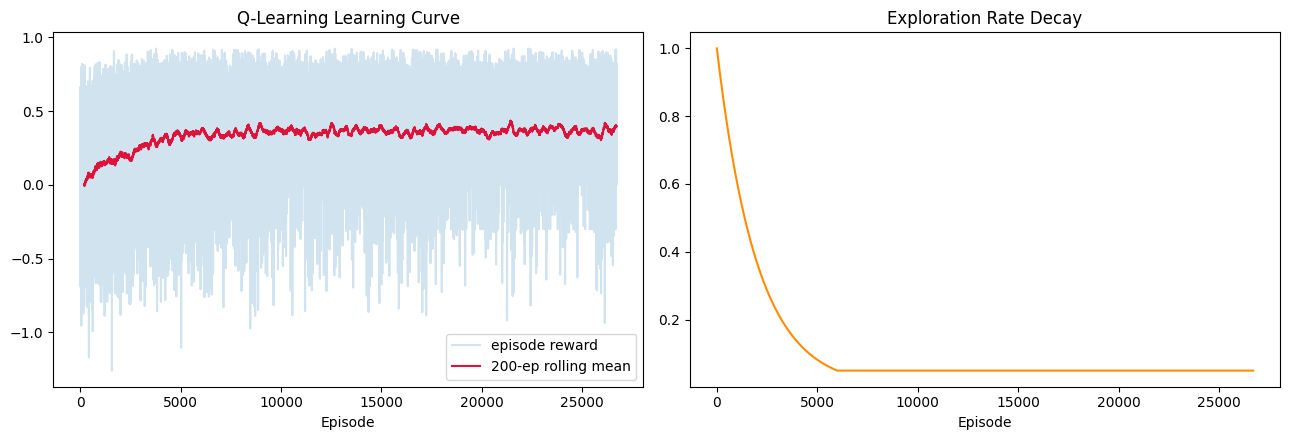

In [18]:
Q_table_default, rl_training_history = train_q_learning(train_df_balanced, 0.60, 0.25, 0.15)
print("Episodes:", len(rl_training_history), "| Q-table entries:", len(Q_table_default))
print("Mean reward, first 500 episodes:", round(rl_training_history["reward"].head(500).mean(), 4))
print("Mean reward, last 500 episodes: ", round(rl_training_history["reward"].tail(500).mean(), 4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(rl_training_history["episode"], rl_training_history["reward"], alpha=0.2, label="episode reward")
axes[0].plot(rl_training_history["episode"], rl_training_history["reward"].rolling(200).mean(), color="crimson", label="200-ep rolling mean")
axes[0].set_title("Q-Learning Learning Curve"); axes[0].set_xlabel("Episode"); axes[0].legend()
axes[1].plot(rl_training_history["episode"], rl_training_history["epsilon"], color="darkorange")
axes[1].set_title("Exploration Rate Decay"); axes[1].set_xlabel("Episode")
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "learning_curve.png"), dpi=120); plt.show()

## 19. Validation-Based Reward-Coefficient + Threshold Selection (precision-constrained)

For each `(ALPHA, BETA, GAMMA)`: train a Q-table on TRAIN, apply it to VALIDATION, then choose the
Low/not-Low threshold as **the most accurate threshold whose bootstrap 10th-percentile precision ≥
`PRECISION_TARGET`** and recall ≥
`MIN_RECALL_FLOOR` (fallback: max F0.5). Candidates are ranked by that constrained validation accuracy,
then precision. A small predefined grid also tunes the individual-risk/classifier-risk score weights while 
keeping the interaction-risk weight fixed; the precision and recall safeguards apply to every candidate. 
**The test set is not used.**

In [19]:
def find_precision_threshold(scores, y_true, precision_target=PRECISION_TARGET,
                             min_recall=MIN_RECALL_FLOOR, grid=None):
    """Maximize accuracy (ties broken by F1) under precision and recall constraints; fall back to max F0.5.
    The bootstrap lower-bound precision must clear the target, while recall stays above the floor.
    If no threshold satisfies the constraint, fall back to max F0.5.
    """
    if grid is None:
        grid = np.round(np.arange(0.20, 0.951, 0.005), 3)

    scores, y_true = np.asarray(scores), np.asarray(y_true)
    B = _boot_idx(len(y_true))
    yb, sb = y_true[B], scores[B]

    rows = []
    for t in grid:
        pred = (scores > t).astype(int)
        m = classification_metrics(y_true, pred)
        m["F0.5"] = fbeta_score(y_true, pred, beta=FALLBACK_BETA, zero_division=0)
        m["Threshold"] = float(t)

        pb = sb > t
        tp = (pb & (yb == 1)).sum(axis=1)
        npos = pb.sum(axis=1)
        m["PrecisionLB"] = float(np.quantile(
            np.where(npos > 0, tp / np.maximum(npos, 1), 0),
            THRESH_PRECISION_QUANTILE
        ))
        rows.append(m)

    tab = pd.DataFrame(rows)
    ok = tab[(tab["PrecisionLB"] >= precision_target) & (tab["Recall"] >= min_recall)]

    if len(ok):
        # Among feasible thresholds tied on accuracy (within THRESH_ACC_TOLERANCE), take the best-balanced one.
        near = ok[ok["Accuracy"] >= ok["Accuracy"].max() - THRESH_ACC_TOLERANCE]
        best = near.sort_values(["F1", "Accuracy", "Precision"], ascending=False).iloc[0]
        rule = (f"max F1 among thresholds within {THRESH_ACC_TOLERANCE} of the best accuracy, "
                f"subject to PrecisionLB >= {precision_target} and Recall >= {min_recall}")
    else:
        best = tab.sort_values("F0.5", ascending=False).iloc[0]
        rule = f"fallback: max F{FALLBACK_BETA}"

    return float(best["Threshold"]), best, rule, tab

In [20]:
PRIVACY_SCORE_WEIGHTS = {"individual": 0.05, "classifier": 0.90, "interaction": 0.05}

def privacy_class(score, low_thr=PRIVACY_LOW_THRESHOLD, high_thr=PRIVACY_HIGH_THRESHOLD):
    return "Low" if score <= low_thr else ("Medium" if score <= high_thr else "High")

def classification_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
    }

def _score_record(row, requested, granted_dict, ep_reward=np.nan):
    granted_set = frozenset(p for p in RL_FEATURES if granted_dict.get(p, 0) == 1)
    requested_set = frozenset(p for p in RL_FEATURES if requested.get(p, 0) == 1)
    meta = make_metadata_vector(row)
    ind = np.mean([individual_risk_normalized(p) for p in granted_set]) if granted_set else 0.0
    cls_r = classifier_risk(granted_dict, requested, meta)
    int_r, triggered = interaction_risk(granted_dict, requested)
    util = sum(utility_map[p] for p in granted_set) / len(requested_set) if requested_set else 0.0
    privacy_score = float(np.clip(
        PRIVACY_SCORE_WEIGHTS["individual"] * ind
        + PRIVACY_SCORE_WEIGHTS["classifier"] * cls_r
        + PRIVACY_SCORE_WEIGHTS["interaction"] * int_r,
        0.0,
        1.0,
    ))
    return {
        "App": row["App"],
        "TrueLabel": int(row["LabelEncoded"]),
        "RequestedPermissions": ";".join(sorted(requested_set)),
        "AllowedPermissions": ";".join(sorted(granted_set)),
        "DeniedPermissions": ";".join(sorted(requested_set - granted_set)),
        "NumRequested": len(requested_set),
        "NumAllowed": len(granted_set),
        "NumDenied": len(requested_set - granted_set),
        "IndividualRisk": ind,
        "MaliciousProbability": cls_r,
        "InteractionRisk": int_r,
        "TriggeredRules": "; ".join(triggered),
        "UtilityScore": util,
        "PrivacyScore": privacy_score,
        "RLReward": ep_reward,
    }

def apply_policy(Q, data_df, a_c, b_c, g_c):
    records = []
    for _, row in data_df.iterrows():
        requested, metadata = make_requested_vector(row), make_metadata_vector(row)
        env = PermissionEnv(requested, a_c, b_c, g_c, metadata)
        state = env.reset()
        episode_reward, done = 0.0, False
        while not done:
            state, reward, done, _ = env.step(greedy_action(Q, state))
            episode_reward += reward
        records.append(_score_record(row, requested, env.granted, episode_reward))
    return pd.DataFrame(records)

_BOOT_IDX_CACHE = {}
def _boot_idx(n):
    if n not in _BOOT_IDX_CACHE:
        _BOOT_IDX_CACHE[n] = np.random.RandomState(RANDOM_STATE).randint(
            0, n, (THRESH_N_BOOT, n)
        )
    return _BOOT_IDX_CACHE[n]

selection_records, trained_qtables, val_results_cache = [], {}, {}
interaction_weight = 0.05
individual_weight_candidates = [0.05, 0.15, 0.30]
for alpha, beta, gamma in COEF_CANDIDATES:
    q_table, history = train_q_learning(train_df_balanced, alpha, beta, gamma)
    trained_qtables[(alpha, beta, gamma)] = (q_table, history)
    validation_results = apply_policy(q_table, val_df, alpha, beta, gamma)
    val_results_cache[(alpha, beta, gamma)] = validation_results

    for individual_weight in individual_weight_candidates:
        classifier_weight = 1.0 - interaction_weight - individual_weight
        validation_scores = np.clip(
            individual_weight * validation_results["IndividualRisk"].values
            + classifier_weight * validation_results["MaliciousProbability"].values
            + interaction_weight * validation_results["InteractionRisk"].values,
            0.0,
            1.0,
        )
        threshold, best, rule, _ = find_precision_threshold(
            validation_scores,
            validation_results["TrueLabel"].values,
        )
        selection_records.append({
            "Alpha": alpha,
            "Beta": beta,
            "Gamma": gamma,
            "Threshold": threshold,
            "Rule": rule,
            "IndividualWeight": individual_weight,
            "ClassifierWeight": classifier_weight,
            "InteractionWeight": interaction_weight,
            "Val_Accuracy": best["Accuracy"],
            "Val_Precision": best["Precision"],
            "Val_Recall": best["Recall"],
            "Val_F1": best["F1"],
            "Val_F0.5": best["F0.5"],
            "Val_PrecisionLB": best["PrecisionLB"],
            "Val_AllowRate": validation_results["NumAllowed"].sum()
            / max(validation_results["NumRequested"].sum(), 1),
            "Val_AvgUtility": validation_results["UtilityScore"].mean(),
            "Val_AvgPrivacyRisk": float(validation_scores.mean()),
        })

selection_df = (
    pd.DataFrame(selection_records)
    .assign(_meets=lambda frame: frame["Val_PrecisionLB"] >= PRECISION_TARGET)
    .sort_values(
        ["_meets", "Val_Accuracy", "Val_Precision", "Val_AvgUtility", "Val_AvgPrivacyRisk"],
        ascending=[False, False, False, False, True],
    )
    .drop(columns="_meets")
    .reset_index(drop=True)
)
display(selection_df)

BEST_ALPHA, BEST_BETA, BEST_GAMMA, BEST_THRESHOLD = selection_df.iloc[0][
    ["Alpha", "Beta", "Gamma", "Threshold"]
]
PRIVACY_SCORE_WEIGHTS = {
    "individual": float(selection_df.iloc[0]["IndividualWeight"]),
    "classifier": float(selection_df.iloc[0]["ClassifierWeight"]),
    "interaction": float(selection_df.iloc[0]["InteractionWeight"]),
}
BEST_Q, BEST_HISTORY = trained_qtables[(BEST_ALPHA, BEST_BETA, BEST_GAMMA)]
best_val_results = val_results_cache[(BEST_ALPHA, BEST_BETA, BEST_GAMMA)]
best_val_results["PrivacyScore"] = np.clip(
    PRIVACY_SCORE_WEIGHTS["individual"] * best_val_results["IndividualRisk"].values
    + PRIVACY_SCORE_WEIGHTS["classifier"] * best_val_results["MaliciousProbability"].values
    + PRIVACY_SCORE_WEIGHTS["interaction"] * best_val_results["InteractionRisk"].values,
    0.0,
    1.0,
)
print(
    f"Selected: ALPHA={BEST_ALPHA}, BETA={BEST_BETA}, GAMMA={BEST_GAMMA}, "
    f"THRESHOLD={BEST_THRESHOLD:.3f} "
    f"(validation accuracy={selection_df.iloc[0]['Val_Accuracy']:.4f}, "
    f"precision={selection_df.iloc[0]['Val_Precision']:.4f})"
)

,Alpha,Beta,Gamma,Threshold,Rule,IndividualWeight,ClassifierWeight,InteractionWeight,Val_Accuracy,Val_Precision,Val_Recall,Val_F1,Val_F0.5,Val_PrecisionLB,Val_AllowRate,Val_AvgUtility,Val_AvgPrivacyRisk
0,0.7,0.20,0.10,0.495,max F1 among thresholds within 0.005 of the be...,0.05,0.90,0.05,0.928926,0.960722,0.948637,0.954641,0.958280,0.953012,0.875388,0.557475,0.736364
1,0.9,0.35,0.25,0.495,max F1 among thresholds within 0.005 of the be...,0.05,0.90,0.05,0.928926,0.960722,0.948637,0.954641,0.958280,0.953012,0.866848,0.557044,0.735560
2,0.6,0.25,0.15,0.495,max F1 among thresholds within 0.005 of the be...,0.05,0.90,0.05,0.928926,0.960722,0.948637,0.954641,0.958280,0.953012,0.866460,0.557002,0.735243
3,0.8,0.30,0.20,0.495,max F1 among thresholds within 0.005 of the be...,0.05,0.90,0.05,0.928926,0.960722,0.948637,0.954641,0.958280,0.953012,0.866848,0.556996,0.735364
4,0.5,0.20,0.15,0.495,max F1 among thresholds within 0.005 of the be...,0.05,0.90,0.05,0.928926,0.960722,0.948637,0.954641,0.958280,0.953012,0.866460,0.556598,0.735146
5,0.4,0.20,0.10,0.495,max F1 among thresholds within 0.005 of the be...,0.05,0.90,0.05,0.928926,0.960722,0.948637,0.954641,0.958280,0.953012,0.863354,0.555983,0.734998
6,0.6,0.40,0.20,0.495,max F1 among thresholds within 0.005 of the be...,0.05,0.90,0.05,0.928926,0.960722,0.948637,0.954641,0.958280,0.953012,0.737189,0.522782,0.728615
7,0.7,0.20,0.10,0.515,max F1 among thresholds within 0.005 of the be...,0.15,0.80,0.05,0.928099,0.961661,0.946541,0.954041,0.958599,0.954045,0.875388,0.557475,0.721541
8,0.9,0.35,0.25,0.515,max F1 among thresholds within 0.005 of the be...,0.15,0.80,0.05,0.928099,0.961661,0.946541,0.954041,0.958599,0.954045,0.866848,0.557044,0.720790
9,0.6,0.25,0.15,0.515,max F1 among thresholds within 0.005 of the be...,0.15,0.80,0.05,0.928099,0.961661,0.946541,0.954041,0.958599,0.954045,0.866460,0.557002,0.720500


Selected: ALPHA=0.7, BETA=0.2, GAMMA=0.1, THRESHOLD=0.495 (validation accuracy=0.9289, precision=0.9607)


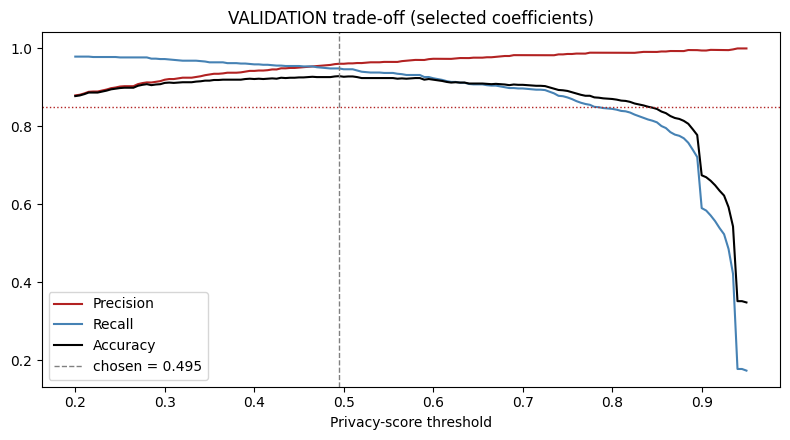

In [21]:
# Precision / recall / accuracy vs threshold on VALIDATION for the selected coefficients
_, _, _, thr_tab = find_precision_threshold(
    val_results_cache[(BEST_ALPHA, BEST_BETA, BEST_GAMMA)]["PrivacyScore"].values,
    val_results_cache[(BEST_ALPHA, BEST_BETA, BEST_GAMMA)]["TrueLabel"].values)
fig, ax = plt.subplots(figsize=(8, 4.5))
for c, col in [("Precision", "firebrick"), ("Recall", "steelblue"), ("Accuracy", "black")]:
    ax.plot(thr_tab["Threshold"], thr_tab[c], label=c, color=col)
ax.axhline(PRECISION_TARGET, ls=":", color="firebrick", lw=1)
ax.axvline(BEST_THRESHOLD, ls="--", color="grey", lw=1, label=f"chosen = {BEST_THRESHOLD:.3f}")
ax.set_xlabel("Privacy-score threshold"); ax.set_title("VALIDATION trade-off (selected coefficients)")
ax.legend(); plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "val_threshold_tradeoff.png"), dpi=120); plt.show()

## 20. Final Test Evaluation (HELD-OUT TEST SET — first and only use)

In [22]:
rl_test_results = apply_policy(BEST_Q, test_df, BEST_ALPHA, BEST_BETA, BEST_GAMMA)
rl_test_results["PrivacyClass"] = rl_test_results["PrivacyScore"].apply(privacy_class)
y_test_true = rl_test_results["TrueLabel"].values
rl_pred = (rl_test_results["PrivacyScore"].values > BEST_THRESHOLD).astype(int)

rl_metrics = classification_metrics(y_test_true, rl_pred)
rl_metrics["F0.5"] = fbeta_score(y_test_true, rl_pred, beta=0.5)
rl_metrics["ROC_AUC"] = roc_auc_score(y_test_true, rl_test_results["PrivacyScore"])
rl_metrics["AvgPrecision"] = average_precision_score(y_test_true, rl_test_results["PrivacyScore"])
rl_cm = confusion_matrix(y_test_true, rl_pred)

print(f"Validation-tuned threshold: {BEST_THRESHOLD:.3f}")
print("=== RL POLICY -- FINAL TEST METRICS ===")
for k, v in rl_metrics.items():
    print(f"  {k:12s}: {v:.4f}")
print("\nConfusion matrix (rows = true [Benign, Malicious], cols = predicted):")
print(rl_cm)
print()
print(classification_report(y_test_true, rl_pred, target_names=["Benign", "Malicious"], digits=4))

Validation-tuned threshold: 0.495
=== RL POLICY -- FINAL TEST METRICS ===
  Accuracy    : 0.9066
  Precision   : 0.9596
  Recall      : 0.9203
  F1          : 0.9395
  F0.5        : 0.9515
  ROC_AUC     : 0.9550
  AvgPrecision: 0.9881

Confusion matrix (rows = true [Benign, Malicious], cols = predicted):
[[219  37]
 [ 76 878]]

              precision    recall  f1-score   support

      Benign     0.7424    0.8555    0.7949       256
   Malicious     0.9596    0.9203    0.9395       954

    accuracy                         0.9066      1210
   macro avg     0.8510    0.8879    0.8672      1210
weighted avg     0.9136    0.9066    0.9089      1210



## 20b. Test-Set Uncertainty (Bootstrap 95% CIs)

In [23]:
n_boot = 2000
rng_boot = np.random.RandomState(RANDOM_STATE)
n_test = len(y_test_true)
boot = {"Accuracy": [], "Precision": [], "Recall": [], "F1": []}
for _ in range(n_boot):
    i = rng_boot.randint(0, n_test, n_test)
    m = classification_metrics(y_test_true[i], rl_pred[i])
    for k in boot:
        boot[k].append(m[k])
ci_df = pd.DataFrame({k: {"Point": rl_metrics[k], "CI_2.5%": np.percentile(v, 2.5), "CI_97.5%": np.percentile(v, 97.5)}
                      for k, v in boot.items()}).T
print(f"Bootstrap over {n_test} test apps, {n_boot} resamples:")
ci_df.round(4)

Bootstrap over 1210 test apps, 2000 resamples:


,Point,CI_2.5%,CI_97.5%
Accuracy,0.9066,0.8893,0.9231
Precision,0.9596,0.9468,0.9716
Recall,0.9203,0.9024,0.9374
F1,0.9395,0.9279,0.9505


In [24]:
rl_classification_metrics_df = pd.DataFrame([{"Model": "RL_Policy", **rl_metrics,
    "AllowRate": rl_test_results["NumAllowed"].sum() / max(rl_test_results["NumRequested"].sum(), 1)}])
rl_privacy_utility_metrics_df = pd.DataFrame([{
    "AvgPrivacyScore": rl_test_results["PrivacyScore"].mean(),
    "AvgPrivacyRisk_Individual": rl_test_results["IndividualRisk"].mean(),
    "AvgMaliciousProbability": rl_test_results["MaliciousProbability"].mean(),
    "AvgInteractionRisk": rl_test_results["InteractionRisk"].mean(),
    "AvgUtility": rl_test_results["UtilityScore"].mean(),
    "AvgPermissionsRequested": rl_test_results["NumRequested"].mean(),
    "AvgPermissionsAllowed": rl_test_results["NumAllowed"].mean(),
    "AvgPermissionsDenied": rl_test_results["NumDenied"].mean(),
    "PermissionAllowRate": rl_test_results["NumAllowed"].sum() / max(rl_test_results["NumRequested"].sum(), 1),
    "PrivacyUtilityScore": rl_test_results["UtilityScore"].mean() - rl_test_results["PrivacyScore"].mean(),
}])
display(rl_classification_metrics_df.round(4))
display(rl_privacy_utility_metrics_df.round(4))

,Model,Accuracy,Precision,Recall,F1,F0.5,ROC_AUC,AvgPrecision,AllowRate
0,RL_Policy,0.9066,0.9596,0.9203,0.9395,0.9515,0.955,0.9881,0.8813


,AvgPrivacyScore,AvgPrivacyRisk_Individual,AvgMaliciousProbability,AvgInteractionRisk,AvgUtility,AvgPermissionsRequested,AvgPermissionsAllowed,AvgPermissionsDenied,PermissionAllowRate,PrivacyUtilityScore
0,0.7237,0.6145,0.7633,0.1209,0.5417,2.1033,1.8537,0.2496,0.8813,-0.1821


## 22. Privacy-Utility Analysis

In [25]:
print("Privacy class distribution on TEST (fixed 0.33 / 0.67 bands):")
print(rl_test_results["PrivacyClass"].value_counts())
print("\nMean PrivacyScore  Benign:", round(rl_test_results.loc[rl_test_results.TrueLabel == 0, "PrivacyScore"].mean(), 4),
      "| Malicious:", round(rl_test_results.loc[rl_test_results.TrueLabel == 1, "PrivacyScore"].mean(), 4))

test_with_genre = rl_test_results.assign(Genre=test_df["Category"].values, Pred=rl_pred)
per_genre = test_with_genre.groupby("Genre").apply(
    lambda d: pd.Series({"N": len(d), "Accuracy": accuracy_score(d.TrueLabel, d.Pred),
                         "Precision": precision_score(d.TrueLabel, d.Pred, zero_division=0),
                         "Recall": recall_score(d.TrueLabel, d.Pred, zero_division=0)}), include_groups=False)
print("\nPer-genre TEST metrics (informational):")
per_genre.round(4)

Privacy class distribution on TEST (fixed 0.33 / 0.67 bands):
PrivacyClass
High      864
Low       231
Medium    115
Name: count, dtype: int64

Mean PrivacyScore  Benign: 0.263 | Malicious: 0.8474

Per-genre TEST metrics (informational):


,N,Accuracy,Precision,Recall
Genre,,,,
Health & Fitness,156.0,0.8269,0.9623,0.6711
Lifestyle,216.0,0.8333,0.8810,0.8409
Medical,40.0,0.9750,1.0000,0.9750
Personalization,230.0,0.8870,0.9577,0.8718
Shopping,61.0,0.8361,0.9107,0.9107
Sports,94.0,0.9787,0.9785,1.0000
Transportation,64.0,1.0000,1.0000,1.0000
Travel & Local,323.0,0.9845,0.9845,1.0000
Weather,26.0,0.7692,0.8947,0.8095
